# NexuStock · Evaluación del impacto en 2024

| | |
|---|---|
| **Proyecto** | NexuStock: gestión y predicción de inventario para una carnicería independiente |
| **Entregable** | Evaluación del impacto operativo y económico · insumo de las tareas 8 y 9 (evaluación económica) |
| **Responsable** | Manuel Bustamante (Data Scientist) |
| **Entradas** | `data/evaluacion/demanda_diaria.csv`, `data/raw/` (catálogo, proveedores, compras, ventas y mermas 2024), `data/processed/stock_diario.csv`, `data/processed/predicciones_prueba_2024.csv` (notebook 03) |
| **Salidas** | Tablas de indicadores y costos en CLP para la evaluación económica (VAN, TIR, payback) |

## Objetivo

Responder **cuánta merma y cuánta venta perdida se evitan** si la carnicería compra según las sugerencias de NexuStock.
Para eso se reproduce todo 2024 día a día con la demanda total de cada producto y se compara la operación registrada
contra la operación con NexuStock.

## Método

| Elemento | Definición |
|---|---|
| Periodo | 1 de enero al 31 de diciembre de 2024 (366 días), nunca usado para entrenar el modelo |
| Demanda | `demanda_latente_kg` de `demanda_diaria.csv`: lo que los clientes pidieron, incluida la venta que no se concretó por falta de stock |
| Inventario | Lotes FIFO: lo más antiguo se vende primero. Un lote recibido el día $r$ se vende hasta el día $r + V$ ($V$ vida útil); lo que queda al vencer es merma |
| Pedidos | Solo en los días de atención del proveedor; llegan en pedido + lead time |
| Decisión | Al inicio de cada día de atención, con el stock disponible y los pedidos en tránsito, igual que el dashboard |
| Regla | La de `backend/src/services/reglas.js`: cobertura hasta la llegada del pedido siguiente, con el peso de cada día de la semana, y tope por vida útil |
| Margen de seguridad | 20 % (además se comparan 10 % y 30 %) |
| Valorización | Merma a costo medio de compra 2024; venta perdida al margen bruto medio 2024 (precio − costo) de cada producto |

In [1]:
import math
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.float_format', '{:,.2f}'.format)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

BASE = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW = BASE / 'data' / 'raw'
PROCESSED = BASE / 'data' / 'processed'
EVALUACION = BASE / 'data' / 'evaluacion'

INI, FIN = pd.Timestamp('2024-01-01'), pd.Timestamp('2024-12-31')
DIAS = pd.date_range(INI, FIN, freq='D')
MARGEN_SEGURIDAD = 0.20  # margen de seguridad de la evaluación (los productos registran 10 %)

# Peso de cada día en la venta semanal, lunes a domingo (EDA 2022-2023), normalizado como en reglas.js
PESOS_DIA = np.array([10.7, 11.8, 12.9, 14.4, 19.5, 23.0, 7.8])
PESOS_DIA = PESOS_DIA / PESOS_DIA.sum()
print('Periodo:', INI.date(), '->', FIN.date(), f'({len(DIAS)} días) · margen {MARGEN_SEGURIDAD:.0%}')
print('Pesos lun..dom:', PESOS_DIA.round(4), 'suma', PESOS_DIA.sum().round(4))

Periodo: 2024-01-01 -> 2024-12-31 (366 días) · margen 20%
Pesos lun..dom: [0.1069 0.1179 0.1289 0.1439 0.1948 0.2298 0.0779] suma 1.0


## 1. Datos

Se cargan el catálogo con el lead time y los días de atención de cada proveedor, la demanda diaria de 2024, el stock al
31-12-2023 (punto de partida), las compras registradas (las de diciembre de 2023 que llegan en enero también cuentan),
las ventas y mermas de 2024, y las predicciones semanales del notebook 03 (`pred_rf` del modelo y `pred_base` del
promedio de 8 semanas).

In [2]:
productos = pd.read_csv(RAW / 'productos.csv').set_index('producto_id')
proveedores = pd.read_csv(RAW / 'proveedores.csv').set_index('proveedor_id')
productos = productos.join(proveedores[['lead_time_dias', 'dias_habiles']], on='proveedor_id')
productos['dias_habiles'] = productos['dias_habiles'].map(lambda s: {int(x) for x in str(s).split(',')})

demanda = pd.read_csv(EVALUACION / 'demanda_diaria.csv', parse_dates=['fecha'])
demanda = demanda[demanda['fecha'].between(INI, FIN)]
dem = (demanda.pivot(index='fecha', columns='producto_id', values='demanda_latente_kg')
       .reindex(DIAS).fillna(0))

stock_diario = pd.read_csv(PROCESSED / 'stock_diario.csv', parse_dates=['fecha'])
stock_inicial = (stock_diario[stock_diario['fecha'] == '2023-12-31']
                 .set_index('producto_id')['stock_cierre'].clip(lower=0))

compras = pd.concat([pd.read_csv(RAW / f'{a}' / f'compras_{a}.csv') for a in (2023, 2024)], ignore_index=True)
compras['fecha_pedido'] = pd.to_datetime(compras['fecha_pedido'])
compras['fecha_recepcion'] = pd.to_datetime(compras['fecha_recepcion'])
compras_2024 = compras[compras['fecha_recepcion'].dt.year == 2024]
ventas_2024 = pd.read_csv(RAW / '2024' / 'ventas_2024.csv')
mermas_2024 = pd.read_csv(RAW / '2024' / 'mermas_2024.csv')

# Precio y costo medio por kg en 2024 (venta y compra registradas)
g_v = ventas_2024.groupby('producto_id')[['total_venta_clp', 'cantidad_kg']].sum()
g_c = compras_2024.groupby('producto_id')[['costo_total_clp', 'cantidad_kg']].sum()
precio = g_v['total_venta_clp'] / g_v['cantidad_kg']
costo = g_c['costo_total_clp'] / g_c['cantidad_kg']

pred = pd.read_csv(PROCESSED / 'predicciones_prueba_2024.csv', parse_dates=['semana'])
print('Productos:', len(productos), '· demanda 2024:', f"{demanda['demanda_latente_kg'].sum():,.0f} kg")
print('Compras 2024:', len(compras_2024), 'recepciones ·', f"{compras_2024['cantidad_kg'].sum():,.0f} kg")
print('Predicciones semanales 2024:', pred.shape, '· semanas', pred['semana'].nunique())
print('Margen bruto medio por kg:', f"{(precio - costo).mean():,.0f} CLP")

Productos: 24 · demanda 2024: 43,514 kg
Compras 2024: 3128 recepciones · 44,969 kg
Predicciones semanales 2024: (1248, 10) · semanas 52
Margen bruto medio por kg: 2,298 CLP


## 2. Operación registrada 2024

Indicadores de lo que ocurrió con las compras hechas por el administrador. La merma por vencimiento se toma del registro
de mermas.

In [3]:
merma_reg = mermas_2024[mermas_2024['motivo'] == 'vencimiento']
registrado = pd.DataFrame({
    'demanda': demanda.groupby('producto_id')['demanda_latente_kg'].sum(),
    'vendido': demanda.groupby('producto_id')['vendido_kg'].sum(),
    'perdida': demanda.groupby('producto_id')['venta_perdida_kg'].sum(),
    'merma': merma_reg.groupby('producto_id')['cantidad_kg'].sum(),
    'comprado': compras_2024.groupby('producto_id')['cantidad_kg'].sum(),
}).fillna(0)
s = registrado.sum()
print(f"Demanda {s.demanda:,.0f} kg · vendido {s.vendido:,.0f} kg")
print(f"Venta perdida {s.perdida:,.0f} kg ({s.perdida / s.demanda:.1%} de la demanda)")
print(f"Merma por vencimiento {s.merma:,.0f} kg ({s.merma / s.comprado:.1%} de lo comprado)")

Demanda 43,514 kg · vendido 42,211 kg
Venta perdida 1,303 kg (3.0% de la demanda)
Merma por vencimiento 2,725 kg (6.1% de lo comprado)


## 3. Reglas de reposición

Son las mismas funciones de `reglas.js`. Con $D$ demanda semanal proyectada, $L$ lead time y $w_j$ peso del día $j$:

- $h_0$ = primer día de atención del proveedor desde hoy (cuando puede emitirse el pedido).
- $h_1$ = siguiente día de atención después de $h_0$ (el pedido siguiente), que llega en $h_1 + L$.
- $D_{\text{rep}} = D \times \sum_{j=\text{hoy}}^{h_1+L} w_j$: la demanda desde hoy hasta la llegada del pedido siguiente, inclusive.
- Pedir si $S < D_{\text{rep}}(1+m)$ o $S < S_{\min}$; cantidad $Q = \min\big(\max(D_{\text{rep}}(1+m),\, S_{\min}(1+m)),\; D/7 \times V\big) - S$.

La regla anterior ($D/7 \times (L+1)$) se conserva solo para comparar. Los casos de prueba son los mismos de
`test/reglas.test.js`.

In [4]:
def dias_cobertura(hoy, lead_time, habiles):
    """Fechas desde hoy hasta la llegada del pedido siguiente, inclusive."""
    h0 = hoy
    while h0.isoweekday() not in habiles:
        h0 += pd.Timedelta(days=1)
    h1 = h0 + pd.Timedelta(days=1)
    while h1.isoweekday() not in habiles:
        h1 += pd.Timedelta(days=1)
    llegada = h1 + pd.Timedelta(days=lead_time)
    return pd.date_range(hoy, llegada, freq='D')


def demanda_reposicion(demanda_semana, lead_time, habiles, hoy):
    """Demanda semanal ponderada por el peso de cada día del horizonte de cobertura."""
    return demanda_semana * PESOS_DIA[dias_cobertura(hoy, lead_time, habiles).weekday].sum()


def demanda_reposicion_anterior(demanda_semana, lead_time):
    """Regla anterior: lead time + 1 día con demanda diaria pareja."""
    return demanda_semana / 7 * (lead_time + 1)


# Mismos casos que test/reglas.test.js
lun = pd.Timestamp('2026-10-05')
casos = [
    ('70 kg, lun-sáb, L1, lunes', demanda_reposicion(70, 1, {1, 2, 3, 4, 5, 6}, lun), 24.76),
    ('70 kg, lun-mié-vie, L1, lunes', demanda_reposicion(70, 1, {1, 3, 5}, lun), 34.83),
    ('70 kg, lun-mié-vie, L1, viernes', demanda_reposicion(70, 1, {1, 3, 5}, pd.Timestamp('2026-10-09')), 50.91),
    ('45 kg, lun-vie, L21, lunes', demanda_reposicion(45, 21, {1, 2, 3, 4, 5}, lun), 145.11),
]
for nombre, obtenido, esperado in casos:
    print(f'{nombre:34s} {obtenido:7.2f}  esperado {esperado:7.2f}  {"OK" if round(obtenido, 2) == esperado else "DIFERENTE"}')

70 kg, lun-sáb, L1, lunes            24.76  esperado   24.76  OK
70 kg, lun-mié-vie, L1, lunes        34.83  esperado   34.83  OK
70 kg, lun-mié-vie, L1, viernes      50.91  esperado   50.91  OK
45 kg, lun-vie, L21, lunes          145.11  esperado  145.11  OK


## 4. Reproducción día a día

Cada día, en este orden: (1) llegan los pedidos de ese día; (2) si el proveedor atiende, se decide el pedido con la
regla; (3) se atiende la demanda con lotes FIFO, y lo que falta es venta perdida; (4) los lotes que vencen ese día pasan
a merma.

In [5]:
def pronostico(fuente):
    """Demanda semanal pronosticada por lunes (filas) y producto (columnas)."""
    return pred.pivot(index='semana', columns='producto_id', values=fuente)


def reproducir(pid, politica, fuente=None, margen=MARGEN_SEGURIDAD, regla='calendario'):
    """
    Reproduce 2024 día a día para un producto con lotes FIFO.
    politica = 'registrada': llegan las compras registradas.
    politica = 'nexustock': se pide lo que sugiere NexuStock al inicio de cada día de atención del proveedor.
    """
    p = productos.loc[pid]
    V = int(p['vida_util_dias']) + 1  # un lote recibido el día r se vende hasta r + vida útil
    L = int(p['lead_time_dias'])
    habiles = p['dias_habiles']
    smin = p['stock_minimo_kg']
    lotes = []  # [último día de venta, kg]
    llegadas = defaultdict(float)
    if stock_inicial.get(pid, 0) > 0:
        lotes.append([INI + pd.Timedelta(days=V - 1), float(stock_inicial[pid])])
    propias = compras[compras['producto_id'] == pid]
    if politica == 'registrada':
        origen = propias[propias['fecha_recepcion'] >= INI]
    else:  # pedidos emitidos en 2023 que llegan en 2024
        origen = propias[(propias['fecha_pedido'] < INI) & (propias['fecha_recepcion'] >= INI)]
        semanal = pronostico(fuente)[pid]
    for r in origen.itertuples():
        llegadas[r.fecha_recepcion] += r.cantidad_kg

    res = dict(demanda=0.0, vendido=0.0, perdida=0.0, merma=0.0, comprado=0.0, pedidos=0, stock_acum=0.0)
    for t in DIAS:
        if llegadas.get(t):
            lotes.append([t + pd.Timedelta(days=V - 1), llegadas.pop(t)])
        # Decisión al inicio del día, como el dashboard: stock disponible + pedidos en tránsito
        if politica == 'nexustock' and t.isoweekday() in habiles:
            D = semanal.get(t - pd.Timedelta(days=t.weekday()), semanal.iloc[-1])  # semana en curso
            posicion = sum(l[1] for l in lotes) + sum(v for k, v in llegadas.items() if k > t)
            if regla == 'calendario':
                drep = demanda_reposicion(D, L, habiles, t)
            else:
                drep = demanda_reposicion_anterior(D, L)
            if posicion < drep * (1 + margen) or posicion < smin:
                objetivo = min(max(drep * (1 + margen), smin * (1 + margen)), D / 7 * V)  # tope por vida útil
                q = math.ceil(max(0.0, objetivo - posicion) * 10 - 1e-9) / 10
                if q > 0:
                    llegadas[t + pd.Timedelta(days=L)] += q
                    res['comprado'] += q
                    res['pedidos'] += 1
        d = dem.at[t, pid]
        res['demanda'] += d
        servir = d
        lotes.sort(key=lambda x: x[0])
        for lote in lotes:
            if servir <= 0:
                break
            q = min(lote[1], servir)
            lote[1] -= q
            servir -= q
        res['vendido'] += d - servir
        res['perdida'] += servir
        res['merma'] += sum(l[1] for l in lotes if l[0] <= t)
        lotes = [l for l in lotes if l[0] > t and l[1] > 1e-9]
        res['stock_acum'] += sum(l[1] for l in lotes)
    if politica == 'registrada':
        res['comprado'] = propias[propias['fecha_recepcion'].dt.year == 2024]['cantidad_kg'].sum()
    res['stock_medio'] = res.pop('stock_acum') / len(DIAS)
    return res


def reproducir_todos(politica, **kw):
    df = pd.DataFrame({pid: reproducir(pid, politica, **kw) for pid in productos.index}).T
    df['merma_clp'] = df['merma'] * costo
    df['margen_perdido_clp'] = df['perdida'] * (precio - costo)
    df['costo_total_clp'] = df['merma_clp'] + df['margen_perdido_clp']
    return df


def resumen(nombre, df):
    s = df.sum()
    return {'politica': nombre,
            'venta_perdida_%': s['perdida'] / s['demanda'] * 100,
            'merma_%_compras': s['merma'] / s['comprado'] * 100,
            'venta_perdida_kg': s['perdida'], 'merma_kg': s['merma'], 'comprado_kg': s['comprado'],
            'stock_medio_kg': s['stock_medio'], 'pedidos': s['pedidos'],
            'merma_M': s['merma_clp'] / 1e6, 'margen_perdido_M': s['margen_perdido_clp'] / 1e6,
            'costo_total_M': s['costo_total_clp'] / 1e6}

## 5. Validación del método

Antes de evaluar NexuStock se comprueba que la reproducción, alimentada con las **compras registradas**, entrega lo que
efectivamente ocurrió en 2024. Si coincide, el método es confiable para evaluar otra política de compras.

In [6]:
val = reproducir_todos('registrada')
v, r = val.sum(), registrado.sum()
validacion = pd.DataFrame({
    'registrado_kg': [r.vendido, r.perdida, r.merma],
    'reproducido_kg': [v.vendido, v.perdida, v.merma],
}, index=['vendido', 'venta perdida', 'merma'])
validacion['diferencia_%'] = (validacion['reproducido_kg'] / validacion['registrado_kg'] - 1) * 100
validacion

,registrado_kg,reproducido_kg,diferencia_%
vendido,"42,211.04","42,217.84",0.02
venta perdida,"1,303.27","1,296.33",-0.53
merma,"2,724.77","2,803.66",2.90


## 6. Políticas comparadas

La operación registrada se compara con NexuStock usando el modelo RF y el promedio de 8 semanas, con margen 10, 20 y
30 %. La última fila muestra la regla anterior (lead time + 1) para justificar el cambio aprobado. Para comparar en
igualdad de condiciones, la fila de la operación registrada usa la reproducción con compras registradas.

In [7]:
filas = [resumen('Operación registrada 2024', val)]
detalle = {}
for fuente, nombre in (('pred_base', 'Promedio 8 semanas'), ('pred_rf', 'Modelo RF')):
    for m in (0.10, 0.20, 0.30):
        clave = f'{nombre} · margen {m:.0%}'
        detalle[clave] = reproducir_todos('nexustock', fuente=fuente, margen=m)
        filas.append(resumen(clave, detalle[clave]))
detalle['Modelo RF · margen 20 % · regla anterior'] = reproducir_todos('nexustock', fuente='pred_rf', regla='anterior')
filas.append(resumen('Modelo RF · margen 20% · regla anterior (lead time + 1)', detalle['Modelo RF · margen 20 % · regla anterior']))
comparacion = pd.DataFrame(filas).set_index('politica')
comparacion[['venta_perdida_%', 'merma_%_compras', 'stock_medio_kg', 'merma_M', 'margen_perdido_M', 'costo_total_M']]

,venta_perdida_%,merma_%_compras,stock_medio_kg,merma_M,margen_perdido_M,costo_total_M
politica,,,,,,
Operación registrada 2024,2.98,6.23,344.82,9.66,2.92,12.58
Promedio 8 semanas · margen 10%,4.06,0.60,240.03,0.82,3.76,4.58
Promedio 8 semanas · margen 20%,3.26,0.94,288.26,1.36,2.93,4.29
Promedio 8 semanas · margen 30%,2.91,1.34,329.24,1.93,2.57,4.50
Modelo RF · margen 10%,3.40,0.79,235.89,1.36,3.08,4.44
Modelo RF · margen 20%,2.62,1.11,284.01,1.96,2.30,4.26
Modelo RF · margen 30%,2.25,1.50,324.83,2.63,1.92,4.56
Modelo RF · margen 20% · regla anterior (lead time + 1),20.52,0.11,93.51,0.12,19.60,19.72


## 7. Costos en CLP

Comparación de la operación registrada con la configuración recomendada: modelo RF y margen 20 %.

In [8]:
nexu = detalle['Modelo RF · margen 20%']
costos = pd.DataFrame({
    'Operación registrada': [val['merma_clp'].sum(), val['margen_perdido_clp'].sum()],
    'NexuStock': [nexu['merma_clp'].sum(), nexu['margen_perdido_clp'].sum()],
}, index=['Merma por vencimiento', 'Margen de venta perdida'])
costos.loc['Total'] = costos.sum()
costos['Ahorro'] = costos['Operación registrada'] - costos['NexuStock']
costos['Ahorro_%'] = costos['Ahorro'] / costos['Operación registrada'] * 100
costos.style.format({c: '${:,.0f}' for c in costos.columns[:3]} | {'Ahorro_%': '{:.1f} %'})

,Operación registrada,NexuStock,Ahorro,Ahorro_%
Merma por vencimiento,"$9,657,734","$1,964,102","$7,693,632",79.7 %
Margen de venta perdida,"$2,923,474","$2,299,080","$624,394",21.4 %
Total,"$12,581,208","$4,263,182","$8,318,026",66.1 %


## 8. Resultado por categoría

In [9]:
cat = productos['categoria']
por_cat = pd.DataFrame({
    'merma_reg_kg': val['merma'].groupby(cat).sum(),
    'merma_nexu_kg': nexu['merma'].groupby(cat).sum(),
    'perdida_reg_kg': val['perdida'].groupby(cat).sum(),
    'perdida_nexu_kg': nexu['perdida'].groupby(cat).sum(),
    'costo_reg_M': val['costo_total_clp'].groupby(cat).sum() / 1e6,
    'costo_nexu_M': nexu['costo_total_clp'].groupby(cat).sum() / 1e6,
})
por_cat['ahorro_M'] = por_cat['costo_reg_M'] - por_cat['costo_nexu_M']
por_cat.loc['Total'] = por_cat.sum()
por_cat

,merma_reg_kg,merma_nexu_kg,perdida_reg_kg,perdida_nexu_kg,costo_reg_M,costo_nexu_M,ahorro_M
categoria,,,,,,,
Cerdo,530.82,88.68,176.04,71.73,2.24,0.45,1.79
Embutidos,13.39,1.77,148.73,91.87,0.38,0.22,0.16
Pescados,438.43,108.23,234.62,261.59,1.74,0.79,0.95
Pollo,"1,289.44",128.28,368.53,551.63,4.01,1.29,2.72
Vacuno,531.58,149.20,368.41,162.49,4.21,1.52,2.70
Total,"2,803.66",476.16,"1,296.33","1,139.31",12.58,4.26,8.32


## 9. Gráficos

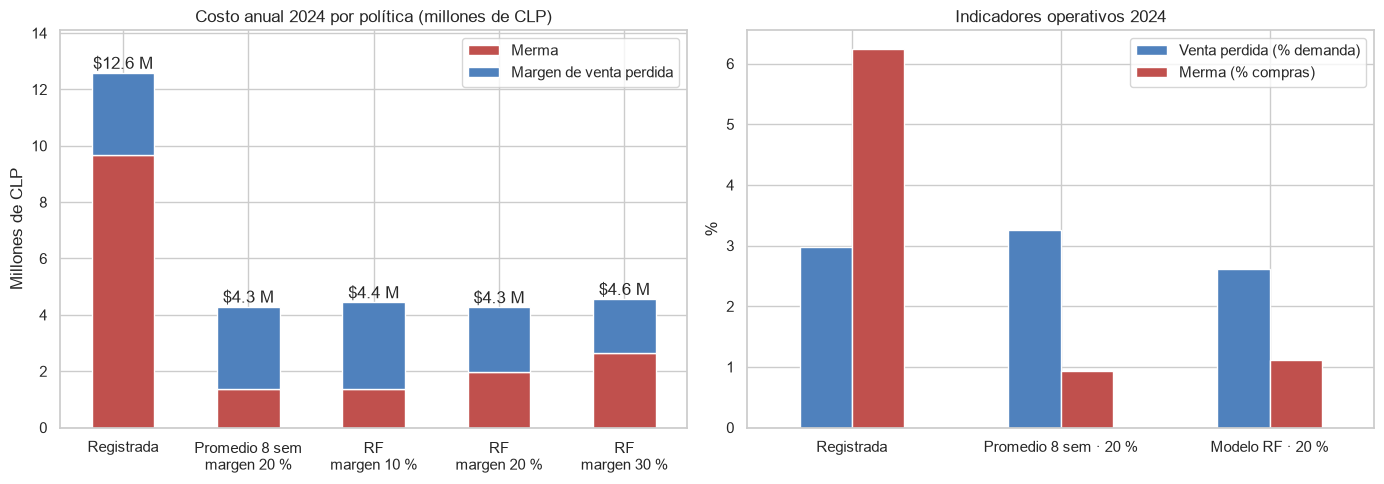

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

graf = comparacion.loc[['Operación registrada 2024', 'Promedio 8 semanas · margen 20%', 'Modelo RF · margen 10%',
                        'Modelo RF · margen 20%', 'Modelo RF · margen 30%'],
                       ['merma_M', 'margen_perdido_M']]
graf.index = ['Registrada', 'Promedio 8 sem\nmargen 20 %', 'RF\nmargen 10 %', 'RF\nmargen 20 %', 'RF\nmargen 30 %']
graf.columns = ['Merma', 'Margen de venta perdida']
graf.plot(kind='bar', stacked=True, ax=axes[0], color=['#c0504d', '#4f81bd'], rot=0)
for i, total in enumerate(graf.sum(axis=1)):
    axes[0].text(i, total + 0.15, f'${total:.1f} M', ha='center')
axes[0].set_title('Costo anual 2024 por política (millones de CLP)')
axes[0].set_ylabel('Millones de CLP')
axes[0].set_ylim(0, graf.sum(axis=1).max() * 1.12)

pct = comparacion.loc[['Operación registrada 2024', 'Promedio 8 semanas · margen 20%', 'Modelo RF · margen 20%'],
                      ['venta_perdida_%', 'merma_%_compras']]
pct.index = ['Registrada', 'Promedio 8 sem · 20 %', 'Modelo RF · 20 %']
pct.columns = ['Venta perdida (% demanda)', 'Merma (% compras)']
pct.plot(kind='bar', ax=axes[1], color=['#4f81bd', '#c0504d'], rot=0)
axes[1].set_title('Indicadores operativos 2024')
axes[1].set_ylabel('%')
plt.tight_layout()
plt.show()

## 10. Métricas para la evaluación económica

Valores anuales que alimentan el flujo de caja de la evaluación económica (VAN, TIR y payback, tareas 8 y 9).

In [11]:
fila_reg = comparacion.loc['Operación registrada 2024']
fila_nexu = comparacion.loc['Modelo RF · margen 20%']
fila_prom = comparacion.loc['Promedio 8 semanas · margen 20%']
metricas = pd.Series({
    'Costo anual operación registrada (CLP)': fila_reg['costo_total_M'] * 1e6,
    'Costo anual con NexuStock (CLP)': fila_nexu['costo_total_M'] * 1e6,
    'Ahorro anual (CLP)': (fila_reg['costo_total_M'] - fila_nexu['costo_total_M']) * 1e6,
    'Ahorro mensual promedio (CLP)': (fila_reg['costo_total_M'] - fila_nexu['costo_total_M']) * 1e6 / 12,
    '  de merma evitada (CLP)': (fila_reg['merma_M'] - fila_nexu['merma_M']) * 1e6,
    '  de margen recuperado (CLP)': (fila_reg['margen_perdido_M'] - fila_nexu['margen_perdido_M']) * 1e6,
    'Merma evitada (kg/año)': fila_reg['merma_kg'] - fila_nexu['merma_kg'],
    'Aporte del modelo vs promedio 8 sem (CLP/año)': (fila_prom['costo_total_M'] - fila_nexu['costo_total_M']) * 1e6,
})
print(metricas.map('{:,.0f}'.format).to_string())

Costo anual operación registrada (CLP)           12,581,208
Costo anual con NexuStock (CLP)                   4,263,182
Ahorro anual (CLP)                                8,318,026
Ahorro mensual promedio (CLP)                       693,169
  de merma evitada (CLP)                          7,693,632
  de margen recuperado (CLP)                        624,394
Merma evitada (kg/año)                                2,327
Aporte del modelo vs promedio 8 sem (CLP/año)        22,847


## 11. Conclusiones

1. **El método es confiable:** con las compras registradas, la reproducción entrega 42.218 kg vendidos (registrado
   42.211), 1.296 kg de venta perdida (1.303) y 2.804 kg de merma (2.725).
2. **La merma baja de 6,2 % a 1,1 % de lo comprado** con NexuStock (modelo RF, margen 20 %): se evitan 2.327 kg al
   año, $7,7 millones. Pollo concentra la mayor reducción (1.289 → 128 kg).
3. **La venta perdida baja de 3,0 % a 2,6 % de la demanda**, aun con menos stock (284 kg promedio frente a 345 kg).
   En pollo y pescados sube algo (vida útil de 3 a 4 días: el tope obliga a pedir justo), y lo compensan vacuno y cerdo.
4. **El costo anual baja de $12,6 a $4,3 millones: ahorro de $8,3 millones al año** (≈ $0,69 millones al mes).
5. **La mayor parte del ahorro viene de la política sistemática** (cobertura con el calendario del proveedor y tope por
   vida útil). El modelo RF, frente al promedio de 8 semanas con el mismo margen, reduce la venta perdida en 20 %
   (3,26 % → 2,62 %) con un costo total similar.
6. **Margen de seguridad de 20 %:** con 10 % la venta perdida sube a 3,4 %; con 30 % la merma sube a 1,5 % y el costo
   total aumenta. 20 % equilibra ambos costos.
7. **La regla anterior (lead time + 1) no sirve:** deja 20,5 % de venta perdida porque no considera los días sin
   atención del proveedor. Esto respalda el control de cambios aprobado.

**Limitaciones:** la base de datos no registra pedidos en tránsito (el administrador los conoce, y la reproducción los
considera); precios y costos son los medios de 2024; no se incluye el costo de mantener stock, que favorecería aún más a
NexuStock porque mantiene menos inventario.